# Validation

1) Map Forecast, Impact

In [30]:
import os
from datetime import UTC, datetime

import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import calendar
import country_converter as coco
from dotenv import find_dotenv, load_dotenv

from poreallas.utils import (
    analysis as analysis_utils,
)
from poreallas.utils import (
    isku as isku_utils,
)
from poreallas.utils import (
    plotting as plotting_utils,
)

In [2]:
load_dotenv(
    find_dotenv("november_local.env", raise_error_if_not_found=True), override=True
)
RUN_MONTH = os.environ["RUN_MONTH"]
# Define Forecast
EFFECTS_URI = os.environ["POREALLAS_EFFECTS_URI"]

In [3]:
N_LEADS = 6

_months = pd.period_range(pd.Period(RUN_MONTH, "M"), periods=N_LEADS, freq="M")
FC_MONTHS = [p.month for p in _months]
FC_PERIOD = slice(
    _months[0].start_time.strftime("%Y-%m-%d"),
    _months[-1].end_time.strftime("%Y-%m-%d"),
)

# Baseline period for Impact
BASELINE_PERIOD = slice("1996-01-01", "2025-12-31")


config = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=False,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)

In [4]:
effect = xr.open_datatree(EFFECTS_URI, consolidated=False)
# Make diagnostic CSV (All Stats by group level) (~ 30 minutes)
# analysis_utils.make_csv(effect, config, group_level="ISO")

In [5]:
effect["/forecast"].attrs

{'poreallas_created_at': '2026-11-09T23:23:16.494843+00:00',
 'poreallas_uid': '35151d30-3699-4871-9de2-000218c0aa96',
 'poreallas_description': 'Forecast ensemble projected temperature mortality effects',
 'poreallas_temperature_uri': 'gs://poreallas-public-20260605/v20261108/parsed/forecast_adj.zarr',
 'poreallas_socioeconomics_uri': 'gs://poreallas-public-20260605/v20260903/parsed/socioeconomics.zarr',
 'poreallas_model_parameters_uri': 'gs://poreallas-public-20260605/v20261006/parsed/gamma.zarr',
 'poreallas_regions_uri': 'gs://poreallas-public-20260605/v20260903/parsed/region_weights.zarr'}

In [6]:
effect["/baseline"].attrs

{'poreallas_created_at': '2026-11-09T23:23:16.494843+00:00',
 'poreallas_uid': '35151d30-3699-4871-9de2-000218c0aa96',
 'poreallas_description': 'Baseline projected temperature mortality effects',
 'poreallas_temperature_uri': 'gs://poreallas-public-20260605/v20260903/parsed/era5_adj.zarr',
 'poreallas_socioeconomics_uri': 'gs://poreallas-public-20260605/v20260903/parsed/socioeconomics.zarr',
 'poreallas_model_parameters_uri': 'gs://poreallas-public-20260605/v20261006/parsed/gamma.zarr',
 'poreallas_regions_uri': 'gs://poreallas-public-20260605/v20260903/parsed/region_weights.zarr'}

## Climate Data

In [23]:
forecast = xr.open_zarr(
    "/home/emily_zuetell/projects/poreallas/data/v2610/v20261006_parsed_forecast.zarr"
)
# Gridded to Impact Region
forecast_ir = isku_utils.grid_to_ir(
    forecast.mean(dim="number").groupby("time.month").mean(), savefile=None
)

/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


In [24]:
_polygons_forecast = analysis_utils.xarray_to_gpd(forecast_ir["tas"], config.polygons)

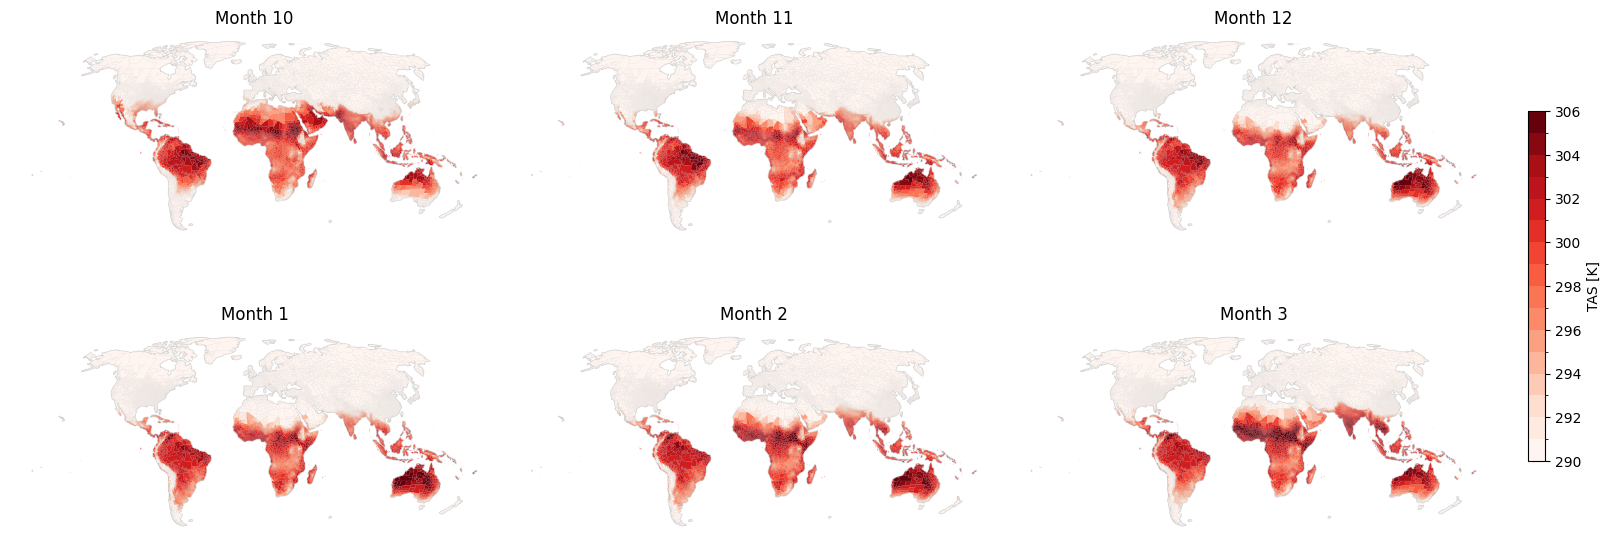

In [25]:
fig = plotting_utils.plot_monthly(
    _polygons_forecast,
    col="tas",
    vmin=290,
    vmax=306,
    n_colors=15,
    cm="Reds",
    sup_title="",
    cbar_label="TAS [K]",
    month_order=config.months,
)

### Forecast Anomaly

In [26]:
forecast = xr.open_zarr("../data/v2610/v20261006_parsed_forecast.zarr")
hindcast = xr.open_zarr("../data/v2610/v20261006_parsed_hindcast.zarr")

anomaly = (
    forecast.mean(dim="number").groupby("time.month").mean()
    - hindcast.groupby("time.month").mean()
)
# Gridded to Impact Region
anomaly_ir = isku_utils.grid_to_ir(anomaly, savefile=None)

_polygons_anomaly = analysis_utils.xarray_to_gpd(anomaly_ir["tas"], config.polygons)

/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


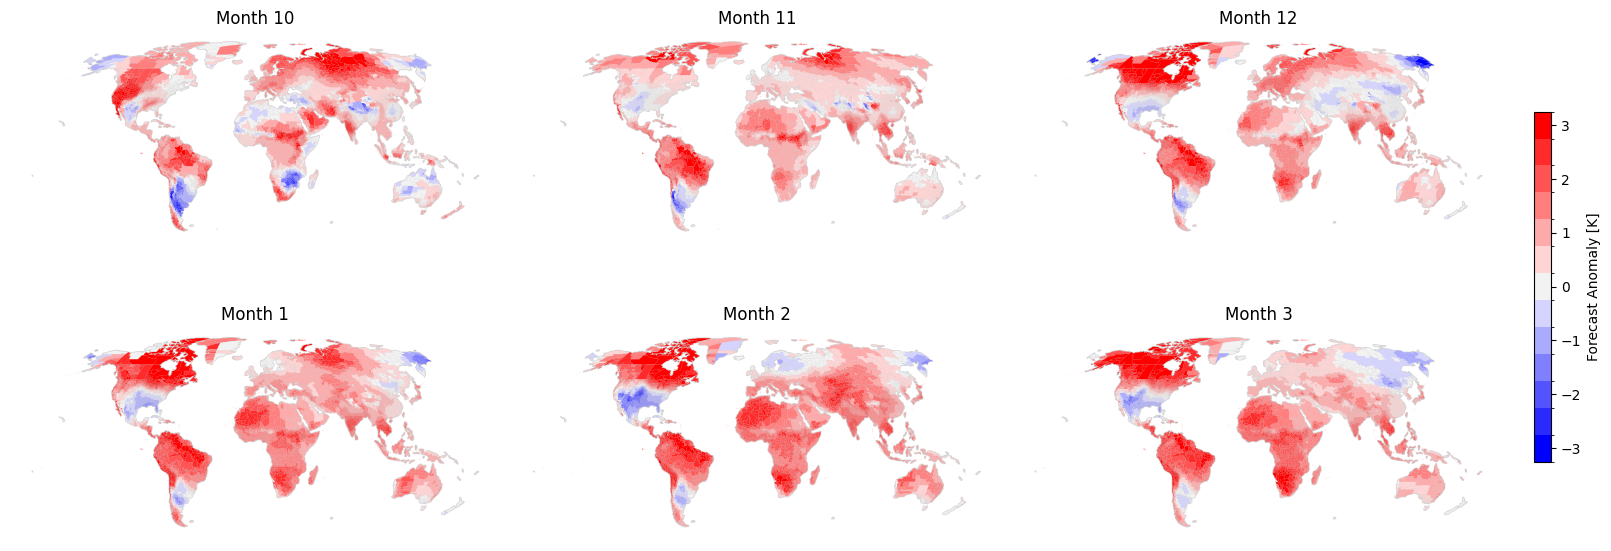

In [27]:
fig = plotting_utils.plot_monthly(
    _polygons_anomaly,
    col="tas",
    vmin=-3,
    vmax=3,
    n_colors=13,
    cm="bwr",
    sup_title="",
    cbar_label="Forecast Anomaly [K]",
    month_order=config.months,
)

### Impact

In [7]:
# Compute impact: forecast - baseline
impact = analysis_utils.compute_impact(
    effect.chunk({dim: -1 for dim in config.dims}),
    config,
    ensemble=True,
)
# Use only the defined 6-months
impact = impact.sel(month=config.months)

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_

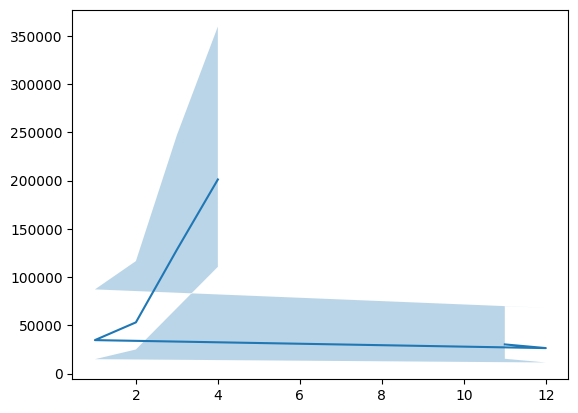

In [ ]:
da = impact.sum(dim = 'region')

q = da.quantile([0.17, 0.5, 0.83], dim=["number", "sample"])



In [ ]:
fig, ax = plt.subplots()
order = [11, 12, 1, 2, 3, 4]
q = q.sel(month=order)

x = np.arange(len(order))
ax.fill_between(x, q.sel(quantile=0.17), q.sel(quantile=0.83), alpha=0.3, label="17–83%")
ax.plot(x, q.sel(quantile=0.5), label="Median")
ax.set_xticks(x, ["Nov", "Dec", "Jan", "Feb", "Mar", "Apr"])
ax.set_ylabel("Total Hot-Only Deaths")

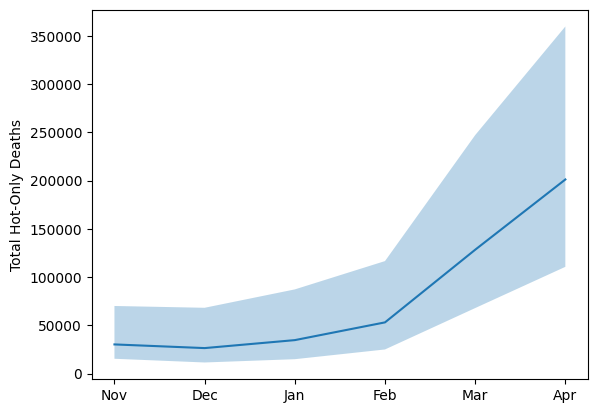

In [ ]:

fig

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


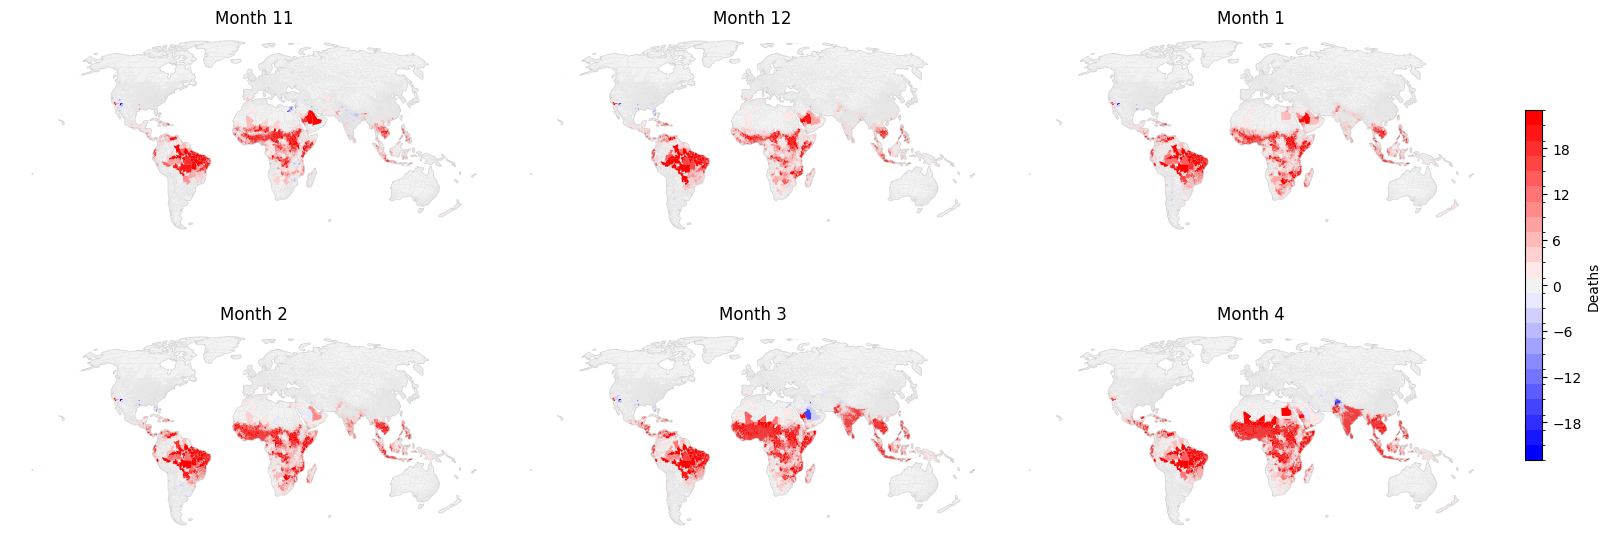

In [8]:
# Plot Impact on a Monthly Basis
_polygons_impact = analysis_utils.xarray_to_gpd(
    impact.mean(dim=["number", "sample"]), config.polygons
)
fig = plotting_utils.plot_monthly(
    _polygons_impact,
    col="age_weighted_impact",
    cm="bwr",
    n_colors=13,
    sup_title="",
    cbar_label=impact.units,
    month_order=config.months,
)

In [9]:
# Aggregate Impact Regions to group_level
group_level = "ISO"  # IR: Impact region, # ADM1: State level, # ISO: Country level
# Use a subset of ensemble members for quick testing (.sel(number = ...))
impact_iso, merge_key, base_cols = analysis_utils.aggregate_impact(
    impact, config, group_level
)

In [ ]:
m = da.mean(["number", "sample"]).transpose("ISO", "month")
total = m.sum("month")
top = total.sortby(total, ascending=False).ISO[:15].values

vals = m.sel(ISO=top).values                 # (15, 6)
gvals = m.sum("ISO").values[None, :]         # (1, 6)
share = vals / vals.sum(axis=1, keepdims=True)
gshare = gvals / gvals.sum(axis=1, keepdims=True)

names = coco.convert(names=list(top), to="name_short")
months = [calendar.month_abbr[int(mo)] for mo in m.month.values]

cmap = plt.get_cmap("YlOrRd")
norm = plt.Normalize(0, max(share.max(), gshare.max()))

def draw_months(ax, v, s, labels):
    im = ax.imshow(s, cmap=cmap, norm=norm, aspect="auto")
    for i, j in np.ndindex(v.shape):
        ax.text(j, i, f"{v[i, j]:,.0f}\n({s[i, j]:.0%})", ha="center", va="center", fontsize=7,
                color="white" if norm(s[i, j]) > 0.6 else "black")
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xticks([])
    return im

def draw_total(ax, v):
    tot = v.sum(axis=1)
    ax.imshow(np.full((len(tot), 1), 0.1), cmap="Greys", vmin=0, vmax=1, aspect="auto")
    for i, t in enumerate(tot):
        ax.text(0, i, f"{t:,.0f}", ha="center", va="center", fontsize=8, fontweight="bold")
    ax.set_xticks([])
    ax.set_yticks([])

fig, axes = plt.subplots(2, 2, figsize=(10, 9),
                         gridspec_kw=dict(height_ratios=[1, 15], width_ratios=[6, 1],
                                          hspace=0.06, wspace=0.03))

draw_months(axes[0, 0], gvals, gshare, ["Global"])
im = draw_months(axes[1, 0], vals, share, names)
draw_total(axes[0, 1], gvals)
draw_total(axes[1, 1], vals)

axes[0, 0].get_yticklabels()[0].set_fontweight("bold")
axes[1, 0].set_xticks(range(len(months)), months)
axes[1, 1].set_xticks([0], ["6-month\ntotal"])
for ax in axes.flat:
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)

fig.colorbar(im, ax=axes.ravel().tolist(), pad=0.02,
             format=mticker.PercentFormatter(1), label="Share of 6-month total")

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


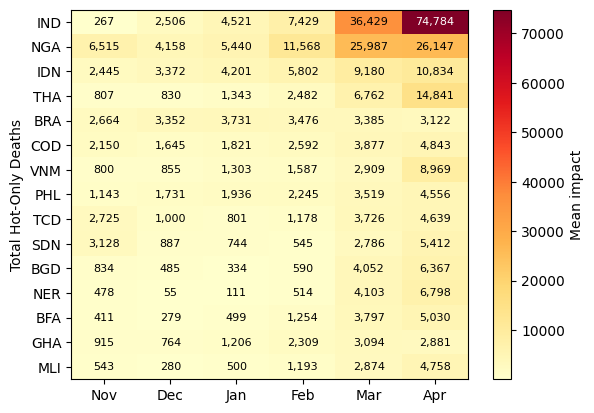

In [26]:
fig